In [90]:
# https://www.analyticsvidhya.com/blog/2024/07/building-agentic-rag-systems-with-langgraph/#h-traditional-rag-system-architecture

import re
from pathlib import Path
from ebooklib import epub, ITEM_DOCUMENT
from bs4 import BeautifulSoup
from operator import itemgetter
from typing import List, TypedDict

from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_chroma import Chroma
from langchain_ollama import OllamaEmbeddings
from langchain_core.prompts import ChatPromptTemplate
from pydantic.v1 import BaseModel, Field
from langchain_ollama import ChatOllama
from langchain_core.runnables import RunnableLambda
from langchain_core.output_parsers import StrOutputParser
from langchain_community.tools.tavily_search import TavilySearchResults
from langgraph.graph import StateGraph, END

from IPython.display import Image, display, Markdown

In [3]:
TAVILY_API_KEY = Path("tavily.tok").read_text().strip()
BOOKS_DIR = "../02_lotm-rag-try2/books"

In [4]:
def clean_html(html_content: bytes) -> str:
    """Strip HTML tags and clean whitespace from epub chapter HTML."""
    soup = BeautifulSoup(html_content, "html.parser")

    # Remove script/style tags
    for tag in soup(["script", "style", "head"]):
        tag.decompose()
    text = soup.get_text(separator="\n")
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

books_dir = Path(BOOKS_DIR)
docs = []
for file in sorted(books_dir.glob("*.epub"), key=lambda x: x.name):
    book = epub.read_epub(file)
    book_title = book.title or file.stem
    i = 0
    for item in book.get_items():
        if item.get_type() != ITEM_DOCUMENT:
            continue
        content = item.get_content()
        text = clean_html(content)
        if len(text) < 100:
            continue
        doc = Document(page_content=text)
        if text.startswith("Chapter"):
            i += 1
            metadata = {"book_title": book_title, "chapter": i}
            doc.metadata = metadata
        else:
            doc.metadata = {"book_title": book_title, "name": "Table of Contents"}
        docs.append(doc)
print(docs[-2].page_content[:100])
len(docs)

Chapter 1394: A New Journey

In a room of an abandoned castle, sunlight shone through the gaps in th


1403

In [5]:
# chunk docs
splitter = RecursiveCharacterTextSplitter(
    chunk_size=2000,
    chunk_overlap=300
)
chunked_docs = splitter.split_documents(docs)
chunked_docs[:3]

[Document(metadata={'book_title': 'Lord of Mysteries Volume 1: Clown', 'name': 'Table of Contents'}, page_content='Table of Contents\n\nFRONT COVER\n\nFULL COVER\n\nVOLUME 1: CLOWN\n\nCOPYRIGHT\n\nSYNOPSIS\n\nCHAPTER 1: CRIMSON\n\nCHAPTER 2: SITUATION\n\nCHAPTER 3: MELISSA\n\nCHAPTER 4: DIVINATION\n\nCHAPTER 5: RITUAL\n\nCHAPTER 6: BEYONDER\n\nCHAPTER 7: CODE NAMES\n\nCHAPTER 8: A NEW ERA\n\nCHAPTER 9: THE NOTEBOOK\n\nCHAPTER 10: THE NORM\n\nCHAPTER 11: REAL CULINARY SKILLS\n\nCHAPTER 12: HERE AGAIN\n\nCHAPTER 13: NIGHTHAWK\n\nCHAPTER 14: THE MEDIUM\n\nCHAPTER 15: THE INVITATION\n\nCHAPTER 16: RAT-BAITING WITH DOGS\n\nCHAPTER 17: SPECIAL OPERATIONS DEPARTMENT\n\nCHAPTER 18: ORIGIN AND CAUSE\n\nCHAPTER 19: SEALED ARTIFACTS\n\nCHAPTER 20: THE FORGETFUL DUNN\n\nCHAPTER 21: AN OLD FRIEND IN A DIFFERENT WORLD\n\nCHAPTER 22: STARTING SEQUENCE\n\nCHAPTER 23: SIDE ARM\n\nCHAPTER 24: PENNY-PINCHER\n\nCHAPTER 25: CATHEDRAL\n\nCHAPTER 26: PRACTICE\n\nCHAPTER 27: SIBLINGS’ DINNER\n\nCHAPTER 28: SE

In [6]:
embed_model = OllamaEmbeddings(model="qwen3-embedding:0.6b")
# Load or create the persisted collection; ingest only when it is empty.
chroma_db = Chroma(
    collection_name="rag_lotm_db",
    embedding_function=embed_model,
    # need to set the distance function to cosine else it uses Euclidean by default
    collection_metadata={"hnsw:space": "cosine"},
    persist_directory="./lotm_db"
)

if chroma_db.get(limit=1)["ids"]:
    print("Loaded existing rag_lotm_db collection; skipping document embedding.")
else:
    chroma_db.add_documents(documents=chunked_docs)
    print(f"Indexed {len(chunked_docs)} chunks into rag_lotm_db.")

Loaded existing rag_lotm_db collection; skipping document embedding.


In [7]:
similarity_threshold_retriever = chroma_db.as_retriever(
    search_type="similarity_score_threshold",
    search_kwargs={"k": 3, "score_threshold": 0.5}
)
query = "Did Klein met Amon?"
top3_docs = similarity_threshold_retriever.invoke(query)
top3_docs

[Document(id='44f6826b-5858-4372-b732-fcada6ce12e0', metadata={'book_title': 'Lord of Mysteries Volume 6: Lightseeker', 'chapter': 73}, page_content='Chapter 1223: That Level\n\nWho am I?\n Just as Klein was about to remove the Historical Void projection, he was taken aback by Amon’s question.\n\nHe controlled himself and didn’t frown. Instead of answering, he asked, “You aren’t Amon’s true body?”\n\nStanding at the edge of the cliff, Amon took a step forward and smiled.\n\n“Of course not.\n\n“You seem to know my true body or my other avatars?”\n\nAlthough the Amon in front of him didn’t take any action, the step “He” took still gave Klein an indescribable pressure. It wasn’t easy for him to keep still without retreating, which would betray his cowardice.\n\nHe grunted and replied in a low voice, “That’s why I’m curious as to why you don’t know me.”\n\n“Are you very famous?” said the Amon who had crawled out of the darkness. “He” then raised “His” hand and adjusted “His” crystal monocl

In [8]:
query = "What is langgraph?"
top3_docs = similarity_threshold_retriever.invoke(query)
top3_docs

No relevant docs were retrieved using the relevance score threshold 0.5


[]

In [9]:
# Data model for LLM output format
class GradeDocuments(BaseModel):
    """Binary score for relevance check on retrieved documents."""
    binary_score: str = Field(description="Documents are relevant to the question, 'yes' or 'no'")

# LLM for grading
llm = ChatOllama(model="qwen3:1.7b", temperature=0)
structured_llm_grader = llm.with_structured_output(GradeDocuments)

# prompt template for grading
SYS_PROMPT = """You are an expert grader assessing relevance of a retrieved document to a user question.
                Follow these instructions for grading:
                  - If the document contains keyword(s) or semantic meaning related to the question, grade it as relevant.
                  - Your grade should be either 'yes' or 'no' to indicate whether the document is relevant to the question or not."""
grade_prompt = ChatPromptTemplate.from_messages([
    ("system", SYS_PROMPT),
    ("human", """Retrieved document:
                {document}
                User question:
                {question}
                """)
])

# Build grader chain
doc_grader = (grade_prompt | structured_llm_grader)
doc_grader

ChatPromptTemplate(input_variables=['document', 'question'], input_types={}, partial_variables={}, messages=[SystemMessagePromptTemplate(prompt=PromptTemplate(input_variables=[], input_types={}, partial_variables={}, template="You are an expert grader assessing relevance of a retrieved document to a user question.\n                Follow these instructions for grading:\n                  - If the document contains keyword(s) or semantic meaning related to the question, grade it as relevant.\n                  - Your grade should be either 'yes' or 'no' to indicate whether the document is relevant to the question or not."), additional_kwargs={}), HumanMessagePromptTemplate(prompt=PromptTemplate(input_variables=['document', 'question'], input_types={}, partial_variables={}, template='Retrieved document:\n                {document}\n                User question:\n                {question}\n                '), additional_kwargs={})])
| _ChatModelBinding(bound=ChatOllama(metadata={'lc_ver

In [10]:
query = "Name all the places where Klein met Amon"
top3_docs = similarity_threshold_retriever.invoke(query)
for doc in top3_docs:
    print("Document:")
    print(doc.page_content[:100])
    grade = doc_grader.invoke({"document": doc.page_content, "question": query})
    print("Grade:", grade)
    print()

Document:
“I need to rest now,” Klein put down his right hand and said frankly.

He believed that Amon would s
Grade: binary_score='yes'

Document:
Chapter 1223: That Level

Who am I?
 Just as Klein was about to remove the Historical Void projectio
Grade: binary_score='yes'

Document:
Under the illumination of the bolts of lightning, Klein carried a leather lantern and walked into th
Grade: binary_score='yes'



In [11]:
query = "What is Klein's full name?"
top3_docs = similarity_threshold_retriever.invoke(query)
for doc in top3_docs:
    print("Document:")
    print(doc.page_content[:100])
    grade = doc_grader.invoke({"document": doc.page_content, "question": query})
    print("Grade:", grade)
    print()

Document:
I really have nothing to do but wait for Miss Justice’s information...
 Klein stood at the end of th
Grade: binary_score='no'

Document:
Klein did not explain further as he walked out the room with a smile. He closed the wooden door behi
Grade: binary_score='No'

Document:
And then he saw Talim Dumon clutch at his heart, his face contorted once again.

“This revelation sh
Grade: binary_score='no'



In [12]:
# Create a RAG prompt for response generation
prompt = """You are an assistant for question-answering tasks.
            Use the following pieces of retrieved context to answer the question.
            If no context is present or if you don't know the answer, just say that you don't know the answer.
            Do not make up the answer unless it is there in the provided context.
            Give a detailed answer and to the point answer with regard to the question.
            Question:
            {question}
            Context:
            {context}
            Answer:
         """

prompt_template = ChatPromptTemplate.from_template(prompt)

qwen = ChatOllama(model="qwen3:1.7b", temperature=0)

# Used for separating context docs with new lines
def format_docs(docs):
    return "\n\n".join(doc.page_content for doc in docs)

# create QA RAG chain
qa_rag_chain = (
    {
        "context": (itemgetter('context') | RunnableLambda(format_docs)),
        "question": itemgetter('question')
    }
        |
    prompt_template
        |
    qwen
        |
    StrOutputParser()
)

In [13]:
query = "Name all the places where Klein met Amon"
top3_docs = similarity_threshold_retriever.invoke(query)
result = qa_rag_chain.invoke({
    "context": top3_docs,
    "question": query
})
print(result)

The context mentions two specific locations where Klein encountered Amon:  
1. **The Hill** (a site where Amon guided Klein to a ruined city, described as a "large city" destroyed by the Cataclysm).  
2. **The Valley** (where Klein and Amon traversed after the lightning bolts, with Amon leading Klein to the ruins of the city).  

Additionally, the **Chaos Sea** is referenced as the location where Amon's "father" (Klein's ancestor) emerged, but this is part of the story's backstory and not a direct meeting place. Sefirah Castle is mentioned as a potential destination for prayer, but it is not explicitly stated as a meeting location with Amon.  

Thus, the primary places are the **hill** and the **valley**.


In [14]:
query = "What is Klein's full name in Lord of Mysteries?"
top3_docs = similarity_threshold_retriever.invoke(query)
result = qa_rag_chain.invoke({
    "context": top3_docs,
    "question": query
})
print(result)

Klein's full name is not explicitly stated in the provided context. The context mentions he is referred to as "Merlin Hermes" and "The Miracle Magician," but these are titles or nicknames, not his full name. Additionally, there is no mention of his actual name beyond these references. Therefore, the answer is that Klein's full name is not present in the given context.


In [15]:
query = "who won the champions league in 2024?"
top3_docs = similarity_threshold_retriever.invoke(query)
result = qa_rag_chain.invoke({
    "context": top3_docs,
    "question": query
})
print(result)

No relevant docs were retrieved using the relevance score threshold 0.5


The provided context does not specify which team won the UEFA Champions League in 2024. The answer is not available in the retrieved information.


In [56]:
# LLM for question rewriting
rewrite_llm = ChatOllama(model="qwen3:0.6b", temperature=0)
# Prompt template for rewriting
SYS_PROMPT = """Act as a question re-writer and perform the following task:
                 - Convert the following input question to a better version that is optimized for web search.
                 - When re-writing, look at the input question and try to reason about the underlying semantic intent / meaning."""

SYS_PROMPT = """Rewrite the user's question into one concise web search query.
Preserve important names, technical terms, dates, and constraints.
Remove conversational filler.
Do not answer the question or introduce unsupported facts.
Return only the search query, without quotes or explanation."""

re_write_prompt = ChatPromptTemplate.from_messages([
    ("system", SYS_PROMPT),
    ("human", """Here is the initial question:
                {question}
                Formulate an improved question.""")
])

# Create rephraser chain
question_rewriter = (
    re_write_prompt
        |
    rewrite_llm
        |
    StrOutputParser()
)

In [59]:
query = "Can you find out whether Chroma recomputes document embeddings when I load an existing persisted collection in LangChain?"
print(question_rewriter.invoke({"question": query}))

Can Chroma recomputes document embeddings when loading a persisted collection in LangChain?


In [64]:
query = "who won the champions league in 2024?"
question_rewriter.invoke({"question": query})

'who won the champions league in 2024?'

In [67]:
tv_search = TavilySearchResults(
    max_results=3,
    tavily_api_key=TAVILY_API_KEY,
    search_depth="advanced",
    max_tokens=10000
)

In [72]:
class GraphState(TypedDict):
    """
    Represents the state of our graph.
    Attributes:
        question: question
        generation: LLM response generation
        web_search_needed: flag of whether to add web search - yes or no
        documents: list of context documents
    """
    question: str
    generation: str
    web_search_needed: str
    documents: List[str]

In [73]:
def retrieve(state):
    """
    Retrieve documents
    Args:
        state (dict): The current graph state
    Returns:
        state (dict): New key added to state, documents - that contains retrieved context documents
    """
    print("---RETRIEVAL FROM VECTOR DB---")
    question = state["question"]
    # Retrieval
    documents = similarity_threshold_retriever.invoke(question)
    return {"documents": documents, "question": question}

In [74]:
def grade_documents(state):
    """
    Determines whether the retrieved documents are relevant to the question
    by using an LLM Grader.
    If any document are not relevant to question or documents are empty - Web Search needs to be done
    If all documents are relevant to question - Web Search is not needed
    Helps filtering out irrelevant documents
    Args:
        state (dict): The current graph state
    Returns:
        state (dict): Updates documents key with only filtered relevant documents
    """
    print("---CHECK DOCUMENT RELEVANCE TO QUESTION---")
    question = state["question"]
    documents = state["documents"]
    # Score each doc
    filtered_docs = []
    web_search_needed = "No"
    if documents:
        for doc in documents:
            score = doc_grader.invoke({"question": question, "document": doc.page_content})
            grade = score.binary_score
            if grade == "yes" or grade == "Yes":
                print("---GRADE: DOCUMENT RELEVANT---")
                filtered_docs.append(doc)
            else:
                print("---GRADE: DOCUMENT NOT RELEVANT---")
                web_search_needed = "Yes"
    else:
        print("---NO DOCUMENTS RETRIEVED---")
        web_search_needed = "Yes"
    return {"documents": filtered_docs, "question": question, "web_search_needed": web_search_needed}

In [75]:
def rewrite_query(state):
    """
    Rewrite the query to produce a better question.
    Args:
        state (dict): The current graph state
    Returns:
        state (dict): Updates question key with a re-phrased or re-written question
    """
    print("---REWRITE QUERY---")
    question = state["question"]
    documents = state["documents"]
    # Re-write question
    better_question = question_rewriter.invoke({"question": question})
    return {"documents": documents, "question": better_question}

In [77]:
def web_search(state):
    """
    Web search based on the re-written question.
    Args:
        state (dict): The current graph state
    Returns:
        state (dict): Updates documents key with retrieved web search results
    """
    print("---WEB SEARCH---")
    question = state["question"]
    documents = state["documents"]
    # web search
    docs = tv_search.invoke(question)
    web_results = "\n\n".join([d["content"] for d in docs])
    web_results = Document(page_content=web_results)
    documents.append(web_results)
    return {"documents": documents, "question": question}

In [78]:
def generate_answer(state):
    """
    Generate answer from context document using LLM
    Args:
        state (dict): The current graph state
    Returns:
        state (dict): New key added to state, generation, that contains LLM generation
    """
    print("---GENERATE ANSWER---")
    question = state["question"]
    documents = state["documents"]
    # RAG generation
    generation = qa_rag_chain.invoke({"context": documents, "question": question})
    return {"documents": documents, "question": question, "generation": generation}

In [79]:
def decide_to_generate(state):
    """
    Determines whether to generate an answer, or re-generate a question.
    Args:
        state (dict): The current graph state
    Returns:
        str: Binary decision for next node to call
    """
    print("---ASSESS GRADED DOCUMENTS---")
    web_search_needed = state["web_search_needed"]
    if web_search_needed == "Yes":
        # All documents have been filtered check_relevance
        # We will re-generate a new query
        print("---DECISION: SOME or ALL DOCUMENTS ARE NOT RELEVANT TO QUESTION, REWRITE QUERY---")
        return "rewrite_query"
    else:
        # We have relevant documents, so generate answer
        print("---DECISION: GENERATE RESPONSE---")
        return "generate_answer"

In [81]:
agentic_rag = StateGraph(GraphState)
# Define the nodes
agentic_rag.add_node("retrieve", retrieve)  # retrieve
agentic_rag.add_node("grade_documents", grade_documents)    # grade documents
agentic_rag.add_node("rewrite_query", rewrite_query)  # transform query
agentic_rag.add_node("web_search", web_search)  # web search
agentic_rag.add_node("generate_answer", generate_answer)  # generate answer
# Build graph
agentic_rag.set_entry_point("retrieve")
agentic_rag.add_edge("retrieve", "grade_documents")
agentic_rag.add_conditional_edges(
    "grade_documents",
    decide_to_generate,
    {"rewrite_query": "rewrite_query", "generate_answer": "generate_answer"}
)
agentic_rag.add_edge("rewrite_query", "web_search")
agentic_rag.add_edge("web_search", "generate_answer")
agentic_rag.add_edge("generate_answer", END)
# Compile
agentic_rag = agentic_rag.compile()

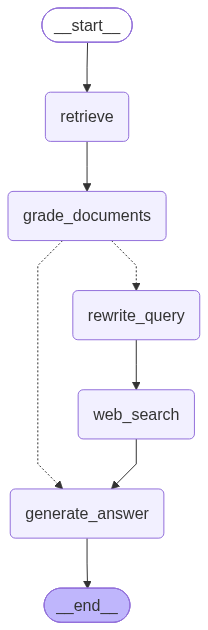

In [83]:
display(Image(agentic_rag.get_graph().draw_mermaid_png()))

In [84]:
query = "Did Klein met Amon?"
response = agentic_rag.invoke({"question": query})

---RETRIEVAL FROM VECTOR DB---
---CHECK DOCUMENT RELEVANCE TO QUESTION---
---GRADE: DOCUMENT NOT RELEVANT---
---GRADE: DOCUMENT RELEVANT---
---GRADE: DOCUMENT NOT RELEVANT---
---ASSESS GRADED DOCUMENTS---
---DECISION: SOME or ALL DOCUMENTS ARE NOT RELEVANT TO QUESTION, REWRITE QUERY---
---REWRITE QUERY---
---WEB SEARCH---
---GENERATE ANSWER---


In [85]:
display(Markdown(response['generation']))

Yes, according to the context, Amon and Klein did meet. The text explicitly states: "Volume 5 ends with Amon meeting Klein and the first half of volume 6 is their journey..." Additionally, it mentions that "Klein met Adam in Livesyed in Groselle's travels," but this is a separate narrative thread. The key point is that Amon and Klein's meeting is confirmed in the context, even if other interactions (like with Adam) are mentioned separately. The answer is directly supported by the provided text.

In [86]:
query = "Name all the places where Klein met Amon"
response = agentic_rag.invoke({"question": query})
response

---RETRIEVAL FROM VECTOR DB---
---CHECK DOCUMENT RELEVANCE TO QUESTION---
---GRADE: DOCUMENT RELEVANT---
---GRADE: DOCUMENT RELEVANT---
---GRADE: DOCUMENT RELEVANT---
---ASSESS GRADED DOCUMENTS---
---DECISION: GENERATE RESPONSE---
---GENERATE ANSWER---


{'question': 'Name all the places where Klein met Amon',
 'generation': 'The context mentions two specific locations where Klein encountered Amon:  \n1. **The Hill** (a site where Amon guided Klein to a ruined city, described as a "large city" destroyed by the Cataclysm).  \n2. **The Valley** (where Klein and Amon traversed after the lightning bolts, with Amon leading Klein to the ruins of the city).  \n\nAdditionally, the **Chaos Sea** is referenced as the location where Amon\'s "father" (Klein\'s ancestor) emerged, but this is part of the story\'s backstory and not a direct meeting place. Sefirah Castle is mentioned as a potential destination for prayer, but it is not explicitly stated as a meeting location with Amon.  \n\nThus, the primary places are the **hill** and the **valley**.',
 'web_search_needed': 'No',
 'documents': [Document(id='e0a527c4-7bfa-4d7a-a799-5e6298a64474', metadata={'book_title': 'Lord of Mysteries Volume 6: Lightseeker', 'chapter': 6}, page_content='“I need to

In [87]:
display(Markdown(response['generation']))

The context mentions two specific locations where Klein encountered Amon:  
1. **The Hill** (a site where Amon guided Klein to a ruined city, described as a "large city" destroyed by the Cataclysm).  
2. **The Valley** (where Klein and Amon traversed after the lightning bolts, with Amon leading Klein to the ruins of the city).  

Additionally, the **Chaos Sea** is referenced as the location where Amon's "father" (Klein's ancestor) emerged, but this is part of the story's backstory and not a direct meeting place. Sefirah Castle is mentioned as a potential destination for prayer, but it is not explicitly stated as a meeting location with Amon.  

Thus, the primary places are the **hill** and the **valley**.

In [88]:
query = "What is the full name of Klein and the aliases he used in the novel 'Lord of Mysteries'"
response = agentic_rag.invoke({"question": query})

---RETRIEVAL FROM VECTOR DB---
---CHECK DOCUMENT RELEVANCE TO QUESTION---
---GRADE: DOCUMENT NOT RELEVANT---
---GRADE: DOCUMENT NOT RELEVANT---
---GRADE: DOCUMENT NOT RELEVANT---
---ASSESS GRADED DOCUMENTS---
---DECISION: SOME or ALL DOCUMENTS ARE NOT RELEVANT TO QUESTION, REWRITE QUERY---
---REWRITE QUERY---
---WEB SEARCH---
---GENERATE ANSWER---


In [89]:
display(Markdown(response['generation']))

The full name of Klein in the novel *Lord of Mysteries* is **Zhou Mingrui**. He is known by several aliases throughout the story, including **Sherlock Moriarty**, **The Fool**, and **World**. These aliases serve as part of his complex identity and narrative role in the novel.